# Four queries before the evaluation

*A few hand-written queries, each with the one document that answers it, and a check that costs almost nothing.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/omnifroodle/couchbase_notebooks/blob/main/notebooks/retrieval/05_four_queries_before_the_evaluation.ipynb)
[![Open in GitHub Codespaces](https://img.shields.io/badge/Open%20in%20Codespaces-2f363d?logo=github&logoColor=white)](https://codespaces.new/omnifroodle/couchbase_notebooks?quickstart=1)

**Claim.** Four hand-written queries are enough to catch a broken embedding setup, if you read how far the right answers sit from the wrong ones instead of how high they score. Choosing between sound models takes more queries, and a full evaluation still has the last word.
**Result.** The highest scores on four queries (0.72) came from the setup with its instruction left off, which has the worst full nDCG@10 of the four candidates (0.70). Separation put that setup last. In random draws of 4 queries from 40, separation preferred the proper setup essentially every time. Picking the best of three sound models agreed with the full evaluation in about half of the draws at 4 queries and 90% at 20.
**Requires.** couchbase · local-embeddings · api-embeddings
**Read** ~10 min · **Run** ~6 min · **Cost** under $0.01 — embeddings only, no chat model

[`retrieval/04`](04_what_a_score_means.ipynb) measures an embedding model properly, and it needs
thousands of human judgements to do it. Most model choices are made long before anyone has
those. Someone tries a few searches, sees scores around 0.7, and moves on.

Those scores say very little. Each model has its own scale, and a setup mistake can raise every
score it produces. There is a cheap check that does better. Write a few queries on unrelated
topics, each with the one document that answers it, and put only those documents in an index.
Now every query has one good result, and the other documents are good results for something
else. A model that suits the corpus puts distance between the two: the right document scores
well above the documents that answer other questions.

**This check is a first screen, not a verdict.** It feeds a proper evaluation and does not
replace one. The last two sections measure how much it can be trusted, and what it cannot see.

**What this notebook does**

1. Writes four queries and their answers by hand.
2. Stores those four documents in Couchbase with a vector for each candidate model and setup.
3. Reads similarity on its own, and shows what it rewards.
4. Reads the separation between good and bad results with SQL++.
5. Runs the full evaluation on a real catalogue, to have something to check the cheap answer against.
6. Finds how many queries the check needs, for two different questions.

In [ ]:
# Setup: load the helpers, install anything missing, check what this notebook needs.
import os
import pathlib
import subprocess
import sys

# Cloned on Colab, where there is no local checkout. Override to test a fork.
REPO_URL = os.environ.get("CBNB_REPO_URL", "https://github.com/omnifroodle/couchbase_notebooks")

try:
    import cbnb
except ModuleNotFoundError:
    here = pathlib.Path.cwd()
    root = next((p for p in [here, *here.parents] if (p / "cbnb" / "__init__.py").exists()), None)
    if root is None:
        # Colab: clone the repo so the committed datasets come with it. Once: a
        # restarted session keeps the files but not sys.path.
        root = pathlib.Path("cbnb-repo").resolve()
        if not root.exists():
            subprocess.check_call(["git", "clone", "--depth", "1", "--quiet", REPO_URL, str(root)])
    sys.path.insert(0, str(root))
    import cbnb

settings = cbnb.bootstrap(requires=["couchbase", "local-embeddings", "api-embeddings"],
                          extras=["metrics", "plots"])

## 1. Four queries, four answers

This cell is the whole input, and it is the one to replace with your own. Each row is a query a
real user might type, with the one document you would want it to find.

Choose queries on **unrelated topics**: here a chair, floor tile, a pet feeder and a power strip.
Each document then serves as a wrong answer for the other three queries, and it is wrong for a
reason nobody could argue with. The documents below are real listings from the
[WANDS](https://github.com/wayfair/WANDS) product catalogue that a person judged an exact match
for the query.

In [2]:
# Write down the queries, each with the one document that answers it.
import pandas as pd

pd.set_option("display.max_colwidth", 90)

pairs = pd.DataFrame([
    {"pair": "chair", "query": "power lift chair",
     "ideal": "kaden 33.1 '' wide velvet power lift assist standard recliner Recliners"},
    {"pair": "tile", "query": "penny round tile",
     "ideal": "1 '' x 1 '' marble penny round mosaic tile Floor & Wall Tile"},
    {"pair": "feeder", "query": "gravity feeder",
     "ideal": "lebistro gravity waterer automatic feeder Dog and Cat Bowls, Feeders & Accessories"},
    {"pair": "surge", "query": "surge protector",
     "ideal": "surgearrest surge protector 3ft cord outlet Switches, Dimmers & Outlets"},
])
pairs

,pair,query,ideal
0,chair,power lift chair,kaden 33.1 '' wide velvet power lift assist standard recliner Recliners
1,tile,penny round tile,1 '' x 1 '' marble penny round mosaic tile Floor & Wall Tile
2,feeder,gravity feeder,"lebistro gravity waterer automatic feeder Dog and Cat Bowls, Feeders & Accessories"
3,surge,surge protector,"surgearrest surge protector 3ft cord outlet Switches, Dimmers & Outlets"


## 2. The candidates

Put in the models you are choosing between. There are three here, plus one deliberate mistake:

| | runs | input markup |
| --- | --- | --- |
| **all-MiniLM-L6-v2** | on this machine | none |
| **Qwen3-Embedding** | your model provider | a task instruction before every query |
| **Qwen3-Embedding, no instruction** | your model provider | the same model with its instruction left off |
| **text-embedding-3-small** | your model provider | none |

The fourth row is the same model with a setup mistake. Qwen3-Embedding's model card asks for an
instruction on every query, and sending the bare text is an easy thing to do, because nothing
fails. It belongs here because a check that cannot catch this is not much of a check.

Providers name the same model differently and do not all carry it, so the cell lists an id per
provider. A candidate your provider lacks is skipped, and the tables name whichever model ran.

In [3]:
# The candidates: each one's id at each provider, and the markup its model card asks for.
from dataclasses import dataclass, replace

from cbnb.embeddings import Embedder

QWEN_TASK = "Given a web search query, retrieve relevant passages that answer the query"
QWEN_IDS = {"nanogpt": "Qwen/Qwen3-Embedding-0.6B", "openrouter": "qwen/qwen3-embedding-8b"}


@dataclass
class Model:
    field: str                    # where this candidate's vector lives on the document
    ids: dict                     # model id per provider; "local" runs on this machine
    query_prefix: str = ""
    document_prefix: str = ""
    variant_of: str = ""          # the field of the candidate this is a changed setup of
    label: str = ""               # added to the model's name, for a changed setup
    embedder: Embedder | None = None


CANDIDATES = [
    Model("minilm", {"local": "sentence-transformers/all-MiniLM-L6-v2"}),
    Model("qwen3", QWEN_IDS, query_prefix=f"Instruct: {QWEN_TASK}\nQuery:"),
    Model("qwen3_plain", QWEN_IDS, variant_of="qwen3", label=" (no instruction)"),
    Model("openai_small", {"nanogpt": "text-embedding-3-small", "openai": "text-embedding-3-small",
                           "openrouter": "openai/text-embedding-3-small"}),
]

MODELS = {}
for c in CANDIDATES:
    backend = "local" if "local" in c.ids else "api"
    model_id = c.ids.get("local") or c.ids.get(settings.llm_provider)
    if model_id is None:
        print(f"skipped {c.field}: no id for provider {settings.llm_provider!r}")
        continue
    MODELS[model_id.split("/")[-1] + c.label] = replace(c, embedder=Embedder(backend, model_id))

pd.DataFrame({name: {"runs": m.embedder.backend, "model id": m.embedder.model,
                     "query prefix": repr(m.query_prefix[:40])} for name, m in MODELS.items()}).T

,runs,model id,query prefix
all-MiniLM-L6-v2,local,sentence-transformers/all-MiniLM-L6-v2,''
Qwen3-Embedding-0.6B,api,Qwen/Qwen3-Embedding-0.6B,"'Instruct: Given a web search query, retr'"
Qwen3-Embedding-0.6B (no instruction),api,Qwen/Qwen3-Embedding-0.6B,''
text-embedding-3-small,api,text-embedding-3-small,''


In [4]:
# Embed the four queries and the four documents with each candidate.
query_vectors = {name: m.embedder.encode([m.query_prefix + q for q in pairs["query"]])
                 for name, m in MODELS.items()}
ideal_vectors = {name: m.embedder.encode([m.document_prefix + t for t in pairs.ideal])
                 for name, m in MODELS.items()}

pd.DataFrame({name: {"texts embedded": len(pairs) * 2, "dims": v.shape[1]}
              for name, v in ideal_vectors.items()}).T

,texts embedded,dims
all-MiniLM-L6-v2,8,384
Qwen3-Embedding-0.6B,8,1024
Qwen3-Embedding-0.6B (no instruction),8,1024
text-embedding-3-small,8,1536


## 3. An index that holds only the answers

Each document is stored once, carrying every candidate's vector, and one Search index covers all
of those fields. Every query then goes to Couchbase once per candidate and gets all four
documents back. Each result is logged as a small document: which candidate, which query, which
document, what score, and whether it was that query's own answer.

In [5]:
# Store each answer once, with every candidate's vector on it, and index them all.
from cbnb.couchbase_io import connect, ensure_collection, ensure_vector_index, upsert_docs, vector_base64, wait_for_index

BUCKET = settings.cb_bucket
SCOPE = "fit_check"
INDEX = "ideals_multi_model"

cluster = connect(settings)
ideals = ensure_collection(cluster, BUCKET, SCOPE, "ideals")

upsert_docs(ideals, {
    row.pair: {"type": "ideals", "text": row.ideal,
               **{m.field: vector_base64(ideal_vectors[name][i]) for name, m in MODELS.items()}}
    for i, row in enumerate(pairs.itertuples(index=False))}, progress=False)

ensure_vector_index(
    cluster, bucket_name=BUCKET, scope_name=SCOPE, collection_name="ideals", index_name=INDEX,
    vector_fields={m.field: ideal_vectors[name].shape[1] for name, m in MODELS.items()},
    base64_vectors=True,
)
wait_for_index(cluster, bucket_name=BUCKET, scope_name=SCOPE, index_name=INDEX, expected=len(pairs))

  indexed 4/4 (ready)   

  indexed 4/4 (ready)   

4

In [6]:
# Search with every query and candidate, and log each result as a document.
import json

from cbnb.couchbase_io import vector_search

where = dict(bucket_name=BUCKET, scope_name=SCOPE, index_name=INDEX)
current = set(pairs.pair)

rows = []
for name, m in MODELS.items():
    for i, q in enumerate(pairs.itertuples(index=False)):
        # A wide k, then only this run's documents: an earlier run's may still be indexed.
        found = [h for h in vector_search(cluster, **where, vector_field=m.field,
                                          query_vector=query_vectors[name][i], k=100, fields=[])
                 if h.id in current]
        rows += [{"model": name, "query_pair": q.pair, "doc": hit.id, "rank": rank,
                  "score": hit.score, "is_good": hit.id == q.pair}
                 for rank, hit in enumerate(found, start=1)]
results = pd.DataFrame(rows)

log = ensure_collection(cluster, BUCKET, SCOPE, "results")
upsert_docs(log, {f"{r['model']}::{r['query_pair']}::{r['doc']}": {"type": "results", **r}
                  for r in json.loads(results.to_json(orient="records"))}, progress=False)
cluster.query(f"CREATE INDEX IF NOT EXISTS results_by_model ON `{BUCKET}`.{SCOPE}.results(model, score)").execute()
print(f"{len(results)} results logged")

64 results logged


## 4. Reading the scores

Start where most people start: how high is the score of the right answer?

In [7]:
# Read the right answer's score for each candidate, in SQL++.
from couchbase.options import QueryOptions

scope = cluster.bucket(BUCKET).scope(SCOPE)


def sql(statement, **params):
    return pd.DataFrame(scope.query(statement, QueryOptions(named_parameters=params)).rows())


this_run = dict(models=list(MODELS), pairs=sorted(current))
summary = sql("""
    SELECT r.model,
           AVG(CASE WHEN r.is_good THEN r.score END)         AS good,
           AVG(CASE WHEN NOT r.is_good THEN r.score END)     AS bad,
           STDDEV(CASE WHEN NOT r.is_good THEN r.score END)  AS spread,
           SUM(CASE WHEN r.is_good AND r.`rank` = 1 THEN 1 ELSE 0 END) AS ranked_first
    FROM results AS r
    WHERE r.model IN $models AND r.query_pair IN $pairs AND r.doc IN $pairs
    GROUP BY r.model
""", **this_run).set_index("model").reindex(list(MODELS))

summary[["good"]].sort_values("good", ascending=False).style.format("{:.3f}")

,good
model,
Qwen3-Embedding-0.6B (no instruction),0.720
all-MiniLM-L6-v2,0.616
Qwen3-Embedding-0.6B,0.591
text-embedding-3-small,0.576


The highest score belongs to Qwen3-Embedding with its instruction left off: 0.72, against 0.59 for the same model set up properly. Someone trying a few searches would choose the broken setup. Leaving off the instruction raises the scores, and the rest of this notebook shows that it improves nothing.

Now the other half of the picture. The check asks how far the good results sit from the bad
ones: for each query, its own document's score minus the average score of the other three.

In [8]:
# Add the bad results, and the distance between good and bad.
n = len(pairs)
summary["separation"] = summary.good - summary.bad
table = summary[["good", "bad", "separation"]].assign(
    **{"ranked first": summary.ranked_first.astype(int).astype(str) + f" of {n}"})
table.style.format({"good": "{:.3f}", "bad": "{:.3f}", "separation": "{:.3f}"})

,good,bad,separation,ranked first
model,,,,
all-MiniLM-L6-v2,0.616,0.058,0.558,4 of 4
Qwen3-Embedding-0.6B,0.591,0.214,0.377,4 of 4
Qwen3-Embedding-0.6B (no instruction),0.720,0.469,0.251,4 of 4
text-embedding-3-small,0.576,0.172,0.404,4 of 4


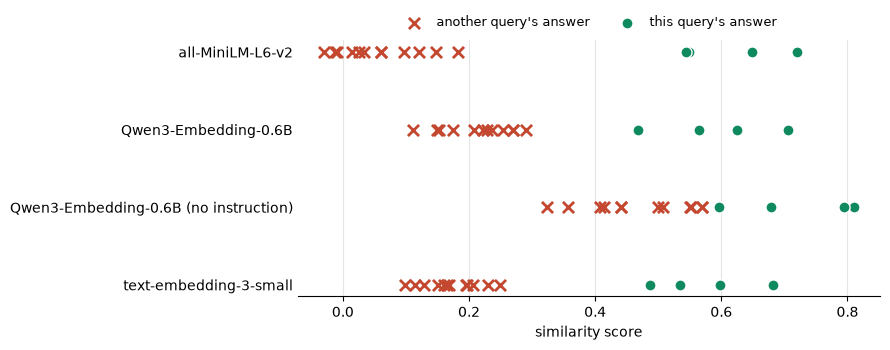

In [9]:
# Draw every score: one row per candidate, the good results against the bad ones.
import matplotlib.pyplot as plt

GOOD, BAD = "#0f8a5f", "#c4472f"

fig, ax = plt.subplots(figsize=(9, 0.8 + 0.7 * len(MODELS)))
for y, name in enumerate(reversed(list(MODELS))):
    mine = results[results.model == name]
    ax.scatter(mine[~mine.is_good].score, [y] * (~mine.is_good).sum(), s=64, marker="x", color=BAD,
               linewidths=2, label="another query's answer" if y == 0 else None, zorder=2)
    ax.scatter(mine[mine.is_good].score, [y] * mine.is_good.sum(), s=64, marker="o", color=GOOD,
               edgecolors="white", linewidths=1, label="this query's answer" if y == 0 else None, zorder=3)
ax.set_yticks(range(len(MODELS)), list(reversed(list(MODELS))))
ax.set_xlabel("similarity score")
ax.grid(axis="x", color="#e5e5e5", zorder=0)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, ncols=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
plt.tight_layout()
plt.show()

Every candidate ranks all four answers first, so the order of the results cannot tell them apart. These topics are easy. The distance can. Without its instruction, Qwen3-Embedding's wrong answers score 0.47, and its lead shrinks to 0.25: the smallest of the four, and a third less than the same model's 0.38 when it is set up properly. In the chart, the red crosses have moved towards the green circles. The candidate with the highest scores has the smallest separation.

Separation is still measured in each model's own cosine units, so comparing it between models
has the problem that similarity had. A model that spreads everything widely will show a wide
gap whether or not it is a better fit. One fix needs nothing beyond these four documents: divide
the separation by the spread of the model's own bad scores, so that each model is measured
against its own noise.

In [10]:
# Put each candidate's separation in its own units: multiples of the spread of its bad scores.
summary["separation / spread"] = summary.separation / summary.spread
summary[["bad", "spread", "separation", "separation / spread"]].style.format("{:.3f}")

,bad,spread,separation,separation / spread
model,,,,
all-MiniLM-L6-v2,0.058,0.067,0.558,8.322
Qwen3-Embedding-0.6B,0.214,0.056,0.377,6.767
Qwen3-Embedding-0.6B (no instruction),0.469,0.084,0.251,2.974
text-embedding-3-small,0.172,0.046,0.404,8.830


Measured in its own units, the broken setup is still last, at about 3 against 7 to 9 for the others. The order at the top changes: MiniLM has the widest raw separation, and text-embedding-3-small leads once each model is measured against its own spread. With four queries that could be luck, and the next two sections find out.

## 5. What the full evaluation says

Four queries took seconds. To find out whether their answer can be trusted, it needs something
to be checked against, and that is the expensive evaluation this check is meant to come before:
every candidate over all 6,482 products, scored by `trec_eval` against the WANDS judgements for
40 queries. This is the one slow step in the notebook, and an exact search in memory is enough
to answer it. [`retrieval/04`](04_what_a_score_means.ipynb) does the same evaluation in Couchbase.

In [11]:
# Embed the whole catalogue with each candidate and score its ranking with trec_eval.
import numpy as np

from cbnb.datasets import load_wands_eval_set
from cbnb.eval import Run, compare, to_qrels

evalset = load_wands_eval_set()
catalogue = pd.DataFrame({
    "doc_id": evalset.products.product_id.astype(str),
    "text": (evalset.products.product_name.fillna("") + " "
             + evalset.products.product_class.fillna("")).str.strip(),
})
questions = pd.DataFrame({"question_id": evalset.queries.query_id.astype(str), "text": evalset.queries["query"]})
judgements = (pd.DataFrame({"question_id": evalset.labels.query_id.astype(str),
                            "doc_id": evalset.labels.product_id.astype(str),
                            "label": evalset.labels.label})
              .drop_duplicates(["question_id", "doc_id"], keep="last"))
qrels = to_qrels(judgements.itertuples(index=False))

catalogue_vectors, question_vectors, runs = {}, {}, []
for name, m in MODELS.items():
    print(name)
    catalogue_vectors[name] = m.embedder.encode([m.document_prefix + t for t in catalogue.text], progress=True)
    question_vectors[name] = m.embedder.encode([m.query_prefix + t for t in questions.text])
    similarity = question_vectors[name] @ catalogue_vectors[name].T
    top = np.argsort(-similarity, axis=1)[:, :50]
    runs.append(Run(name, {questions.question_id.iat[i]: [(catalogue.doc_id.iat[j], float(similarity[i, j])) for j in top[i]]
                           for i in range(len(questions))}))

full = compare(runs, qrels, measures=["nDCG@10"])
full.style.format("{:.3f}").set_caption(f"n = {len(questions)} queries, {len(catalogue):,} products")

all-MiniLM-L6-v2
Qwen3-Embedding-0.6B
Qwen3-Embedding-0.6B (no instruction)
text-embedding-3-small


,nDCG@10
all-MiniLM-L6-v2,0.774
Qwen3-Embedding-0.6B,0.777
Qwen3-Embedding-0.6B (no instruction),0.701
text-embedding-3-small,0.797


The same check can now run on all 40 of those queries. Each gets one ideal document, its first
`Exact` judgement, fixed by a rule so that no model has a say in it. The index holds only those
40 documents, as in section 3, and the arithmetic is the same. Next to it is what the full
evaluation found.

In [12]:
# Run the check on all 40 queries, and set it beside the full evaluation.
row_of = {d: i for i, d in enumerate(catalogue.doc_id)}
exact = judgements[(judgements.label == "Exact") & judgements.doc_id.isin(row_of)]
ideal_row = exact.groupby("question_id").doc_id.first().map(row_of)
question_ids = [q for q in questions.question_id if q in ideal_row.index]
question_row = {q: i for i, q in enumerate(questions.question_id)}


def check(name, ids):
    """The separation check, for these queries and an index of only their ideal documents."""
    scores = question_vectors[name][[question_row[q] for q in ids]] @ catalogue_vectors[name][[ideal_row[q] for q in ids]].T
    is_bad = ~np.eye(len(ids), dtype=bool)
    good, bad = np.diag(scores), scores[is_bad].reshape(len(ids), -1)
    return {"good": good.mean(), "bad": bad.mean(), "separation": (good - bad.mean(axis=1)).mean(),
            "separation / spread": (good - bad.mean(axis=1)).mean() / scores[is_bad].std(ddof=1),
            "ranked first": (good > bad.max(axis=1)).mean()}


all_queries = pd.DataFrame({name: check(name, question_ids) for name in MODELS}).T
all_queries.insert(0, "full nDCG@10", full.loc[list(MODELS), "nDCG@10"])
all_queries.style.format("{:.3f}").format("{:.0%}", subset=["ranked first"])

,full nDCG@10,good,bad,separation,separation / spread,ranked first
all-MiniLM-L6-v2,0.774,0.521,0.128,0.393,3.487,92%
Qwen3-Embedding-0.6B,0.777,0.504,0.263,0.241,3.217,85%
Qwen3-Embedding-0.6B (no instruction),0.701,0.703,0.515,0.189,2.672,68%
text-embedding-3-small,0.797,0.534,0.221,0.313,3.787,90%


The full evaluation puts text-embedding-3-small first at about 0.80, the other two sound models about two points behind, and the broken setup well below at 0.70. The check agrees about the broken setup: on all 40 queries it again has the highest scores and the lowest separation. `separation / spread` also puts text-embedding-3-small first. Raw separation does not. It gives MiniLM the widest gap by some distance.

MiniLM also ranks the right document first most often here, 92% against 90%, and does not lead the full evaluation. That is not a contradiction. These queries ask whether a model can tell unrelated subjects apart. A catalogue asks whether it can find the right product among many similar ones, and an index of a few answers holds none of those near misses.

## 6. How many queries does it take?

Four queries is an arbitrary number. The queries below are drawn at random from the 40, many
times over, and the check is asked two questions each time.

- **Is this setup broken?** Does the candidate with its instruction beat the same model without it?
- **Which model is best?** Does `separation / spread` pick the model that the full evaluation
  ranks first? The changed setup is left out of this one.

In [13]:
# Draw queries at random, and see how often the check answers each question correctly.
name_of_field = {m.field: name for name, m in MODELS.items()}
setups = [(name_of_field[m.variant_of], name) for name, m in MODELS.items() if m.variant_of in name_of_field]
contenders = [name for name, m in MODELS.items() if not m.variant_of]
best_model = full.loc[contenders, "nDCG@10"].idxmax()

DRAWS = 2000
rng = np.random.default_rng(1729)
agreement = {}
for size in (4, 10, 20):
    setup_caught, raw_setup_caught, model_found, raw_model_found = 0, 0, 0, 0
    for _ in range(DRAWS):
        ids = list(rng.choice(question_ids, size, replace=False))
        s = {name: check(name, ids) for name in MODELS}
        setup_caught += all(s[a]["separation / spread"] > s[b]["separation / spread"] for a, b in setups)
        raw_setup_caught += all(s[a]["separation"] > s[b]["separation"] for a, b in setups)
        model_found += max(contenders, key=lambda c: s[c]["separation / spread"]) == best_model
        raw_model_found += max(contenders, key=lambda c: s[c]["separation"]) == best_model
    agreement[size] = {"catches the broken setup: separation": raw_setup_caught / DRAWS,
                       "catches the broken setup: separation / spread": setup_caught / DRAWS,
                       f"picks {best_model}: separation": raw_model_found / DRAWS,
                       f"picks {best_model}: separation / spread": model_found / DRAWS}
agreement = pd.DataFrame(agreement).rename_axis(columns="queries")
agreement.style.format("{:.0%}")

queries,4,10,20
catches the broken setup: separation,100%,100%,100%
catches the broken setup: separation / spread,78%,95%,100%
picks text-embedding-3-small: separation,5%,0%,0%
picks text-embedding-3-small: separation / spread,49%,70%,90%


The two questions need very different amounts of evidence.

**A broken setup shows up with four queries.** Comparing a model with itself, plain separation preferred the proper setup in essentially every draw. Dividing by the spread only adds noise here, because both rows are the same model.

**Choosing between sound models takes many more.** Raw separation almost never picks text-embedding-3-small, and more queries make that worse, because it is measuring each model's scale. `separation / spread` agrees with the full evaluation in about half of the draws at 4 queries, 70% at 10 and 90% at 20; chance among three would be a third. These three models are within about two points of each other on nDCG@10, so this is a hard comparison. And none of these candidates is plainly unsuited to this catalogue, so this run does not show how the check treats one that is.

So use it as a screen. Compare setups of one model with plain separation, compare different models with `separation / spread` over 20 or so queries, and send whatever passes to a full evaluation.

## Where to take this

- **Run it before you collect judgements.** Your own pairs go in section 1 and your candidates in
  section 2. Models that fail here are not worth judging for, and the ones that pass go on to
  the full evaluation in [`retrieval/04`](04_what_a_score_means.ipynb).
- **Keep it as a smoke test.** Log the separation for the setup you run, and repeat the check
  after changing a provider, a model version or a prompt format. It takes seconds, and a broken
  setup shows up as a drop.
- **Add a harder set.** Unrelated topics test whether a model tells your subjects apart. A second
  set of pairs on neighbouring topics starts to test the near misses that a full catalogue holds.
- **Then set the threshold.** Separation says whether a model can tell good from bad. How to cut
  between them is a per-model measurement, and `retrieval/04` makes it.

## What produced these results

Every number above came from the models below. A different model, or the same name served
differently, will give different numbers.

In [14]:
# Name the models that produced the results above.
cbnb.run_card()

,model,how it ran
Embeddings,Qwen/Qwen3-Embedding-0.6B,"via NanoGPT; 13,060 texts, 13,060 from cache"
Embeddings,sentence-transformers/all-MiniLM-L6-v2,"on this machine; 6,530 texts, 6,530 from cache"
Embeddings,text-embedding-3-small,"via NanoGPT; 6,530 texts, 6,530 from cache"


In [15]:
# Optional clean-up: delete what this notebook created. Uncomment to run.
# from cbnb.couchbase_io import drop_demo_data
# drop_demo_data(cluster, BUCKET, SCOPE)